# A2 — Đọc và trực quan hóa dữ liệu WIDER FACE (định dạng YOLO5Face)

Notebook này đọc **từng mẫu** (lazy) trong tập train đã chuyển sang định dạng YOLO5Face và vẽ bounding box + 5 landmark.
Không nạp toàn bộ dataset, không huấn luyện, không ghi file theo mặc định.

## 1. Import và tìm thư mục gốc của repo

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch


def find_repo_root(start: Path | None = None) -> Path:
    """Đi ngược từ cwd lên các thư mục cha cho tới khi gặp common/plotting.py."""
    start = (start or Path.cwd()).resolve()
    for d in (start, *start.parents):
        if (d / "common" / "plotting.py").is_file():
            return d
    raise FileNotFoundError(f"Không tìm thấy repo root (common/plotting.py) từ {start}")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from common.plotting import setup_style, save_fig
from common.utils import set_seed, get_device

setup_style()
set_seed(42)
DEVICE = get_device()

## 2. Định dạng nhãn YOLO5Face

Mỗi ảnh `xxx.jpg` đi kèm `xxx.txt` (cùng stem). Mỗi dòng có **15 cột**, tất cả chuẩn hóa về [0, 1] theo kích thước ảnh:

`class cx cy w h  x1 y1  x2 y2  x3 y3  x4 y4  x5 y5`

- 5 landmark: mắt trái, mắt phải, mũi, khóe miệng trái, khóe miệng phải.
- Landmark bị thiếu được ghi là `-1 / width` → giá trị **âm** ⇒ coi như không hợp lệ (mask theo từng cặp x, y).
- File nhãn rỗng = ảnh không có khuôn mặt.

In [2]:
TRAIN_DIR = REPO_ROOT.parent / "widerface_yolo" / "train"
N_COLS, N_LANDMARKS = 15, 5


def parse_label_line(line: str, label_path: Path, lineno: int) -> np.ndarray:
    parts = line.split()
    if len(parts) != N_COLS:
        raise ValueError(f"{label_path.name}:{lineno}: cần {N_COLS} cột, nhận {len(parts)}")
    try:
        row = np.array([float(p) for p in parts], dtype=np.float64)
    except ValueError as e:
        raise ValueError(f"{label_path.name}:{lineno}: giá trị không phải số ({e})") from None
    if not np.all(np.isfinite(row)):
        raise ValueError(f"{label_path.name}:{lineno}: có giá trị NaN/inf")
    cls = row[0]
    if cls < 0 or cls != int(cls):
        raise ValueError(f"{label_path.name}:{lineno}: class phải là số nguyên không âm, nhận {cls}")
    cx, cy, w, h = row[1:5]
    if not (w > 0 and h > 0 and 0 <= cx <= 1 and 0 <= cy <= 1 and w <= 1 and h <= 1):
        raise ValueError(f"{label_path.name}:{lineno}: bbox chuẩn hóa không hợp lệ {row[1:5].tolist()}")
    return row


def load_train_sample(image_path) -> dict:
    """Đọc một ảnh + nhãn YOLO5Face, trả về toạ độ pixel.

    Trả về dict:
        image      : np.uint8 (H, W, 3) RGB
        boxes      : float32 (N, 4) xyxy pixel
        landmarks  : float32 (N, 5, 2) pixel (điểm thiếu = NaN)
        lmk_valid  : bool (N, 5)
        classes    : int64 (N,)
        image_path, label_path
    """
    image_path = Path(image_path)
    label_path = image_path.with_suffix(".txt")
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {image_path}")
    if not label_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy file nhãn: {label_path}")

    with Image.open(image_path) as im:
        image = np.array(im.convert("RGB"))
    H, W = image.shape[:2]

    rows = [parse_label_line(line, label_path, i)
            for i, line in enumerate(label_path.read_text().splitlines(), 1) if line.strip()]
    labels = np.stack(rows) if rows else np.zeros((0, N_COLS))

    cx, cy, w, h = (labels[:, k] for k in range(1, 5))
    boxes = np.stack([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H], axis=1)

    lmk = labels[:, 5:].reshape(-1, N_LANDMARKS, 2)
    lmk_valid = np.all(lmk >= 0, axis=2)               # toạ độ âm = landmark bị thiếu
    lmk_px = lmk * np.array([W, H])
    lmk_px[~lmk_valid] = np.nan

    return {
        "image": image,
        "boxes": boxes.astype(np.float32).reshape(-1, 4),
        "landmarks": lmk_px.astype(np.float32),
        "lmk_valid": lmk_valid,
        "classes": labels[:, 0].astype(np.int64),
        "image_path": image_path,
        "label_path": label_path,
    }

## 3. Hàm vẽ ảnh, bbox và landmark hợp lệ

In [3]:
LMK_COLORS = ["tab:red", "tab:orange", "tab:green", "tab:blue", "tab:purple"]


def plot_sample(sample: dict, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(sample["image"])
    for (x1, y1, x2, y2) in sample["boxes"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1.2))
    for pts, valid in zip(sample["landmarks"], sample["lmk_valid"]):
        for k in np.flatnonzero(valid):
            ax.scatter(*pts[k], s=8, c=LMK_COLORS[k])
    n = len(sample["boxes"])
    ax.set_title(f"{sample['image_path'].name} — {n} khuôn mặt, {int(sample['lmk_valid'].any(1).sum())} có landmark")
    ax.axis("off")
    return ax.figure

## 4. Ví dụ: một ảnh train

Chỉ lấy ảnh đầu tiên có file nhãn tương ứng (dùng iterator, không liệt kê toàn bộ). Đặt `SAVE = True` để lưu hình.

Ảnh: (768, 1024, 3) | boxes: (4, 4) | landmarks: (4, 5, 2) | classes: [0]
Tensor: (3, 768, 1024)


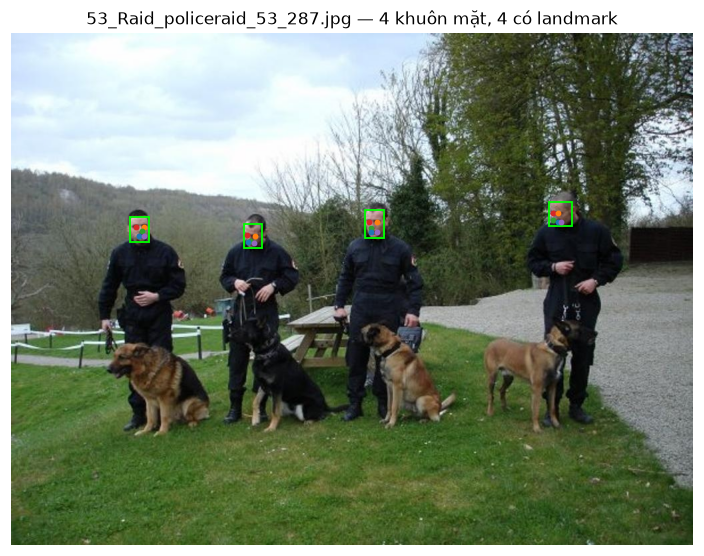

In [4]:
SAVE = True

if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(f"Không thấy thư mục train: {TRAIN_DIR}")
example_path = next(p for p in TRAIN_DIR.glob("*.jpg") if p.with_suffix(".txt").is_file())

sample = load_train_sample(example_path)
print("Ảnh:", sample["image"].shape, "| boxes:", sample["boxes"].shape,
      "| landmarks:", sample["landmarks"].shape, "| classes:", np.unique(sample["classes"]))

# Chuyển sang tensor khi cần đưa vào model
img_t = torch.from_numpy(sample["image"]).permute(2, 0, 1).float() / 255.0
print("Tensor:", tuple(img_t.shape))

fig = plot_sample(sample)
if SAVE:
    save_fig(fig, REPO_ROOT / "A2" / "figures", "train_sample", show=True)

plt.show()

## 5. Xem một ảnh train theo tên

`show_train_image` nhận **tên file** (vd. `abc.jpg`) hoặc **stem** không đuôi (vd. `abc`), tìm ảnh tương ứng trong `TRAIN_DIR` (đuôi `.jpg`/`.jpeg`/`.png`, không phân biệt hoa thường), rồi đọc bằng `load_train_sample` và vẽ bằng `plot_sample`.

- Chỉ chấp nhận tên file thuần — đường dẫn chứa `/`, `\\`, `..` bị từ chối (không đọc ra ngoài `TRAIN_DIR`).
- Không tìm thấy → `FileNotFoundError`; stem khớp nhiều ảnh (vd. `abc.jpg` và `abc.png`) → `ValueError`.
- Trả về dict `sample` để kiểm tra thêm.

In [9]:
import glob

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}


def show_train_image(image_name: str, train_dir: Path = TRAIN_DIR) -> dict:
    """Hiển thị ảnh train theo tên file (có đuôi) hoặc stem (không đuôi)."""
    name = str(image_name).strip()
    if not name or name in {".", ".."} or "/" in name or "\\" in name or Path(name).name != name:
        raise ValueError(f"Chỉ nhận tên file, không nhận đường dẫn: {image_name!r}")
    train_dir = Path(train_dir).resolve()
    if not train_dir.is_dir():
        raise FileNotFoundError(f"Không thấy thư mục train: {train_dir}")

    # Có đuôi ảnh hợp lệ → khớp đúng đuôi đó; ngược lại coi cả chuỗi là stem
    suffix = Path(name).suffix.lower()
    stem, wanted = (Path(name).stem, {suffix}) if suffix in IMAGE_EXTS else (name, IMAGE_EXTS)
    matches = [p for p in train_dir.glob(f"{glob.escape(stem)}.*")
               if p.stem == stem and p.suffix.lower() in wanted
               and p.is_file() and p.resolve().parent == train_dir]

    if not matches:
        raise FileNotFoundError(f"Không tìm thấy ảnh {name!r} trong {train_dir}")
    if len(matches) > 1:
        raise ValueError(f"Tên {name!r} khớp nhiều ảnh: {sorted(p.name for p in matches)}")

    sample = load_train_sample(matches[0])
    plt = plot_sample(sample)
    plt.show()
    save_fig(plt, REPO_ROOT / "A2" / "figures", f"{image_name}_bbox", show=True)
    return sample

/var/folders/jy/blrc_xyd4ds1l2dh2z4g05dw0000gn/T/ipykernel_11579/3031254367.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


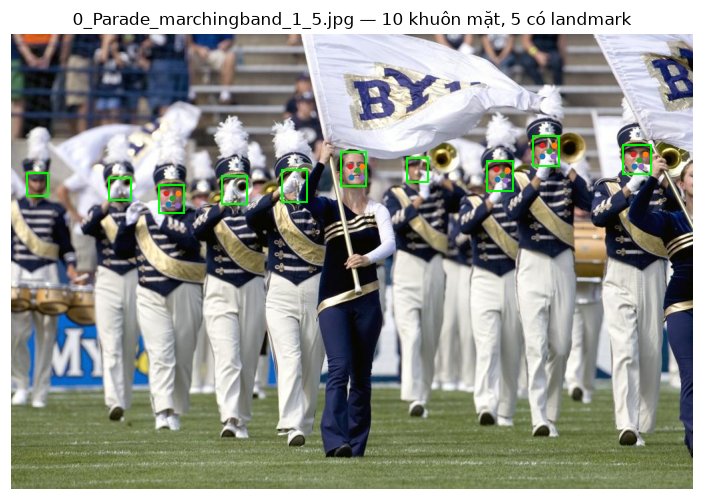

In [10]:
sample = show_train_image("0_Parade_marchingband_1_5")